# 🔬 03 - Exploratory Autoencoder, Multi-Head Attention & DDQN Integration

**Author**: Parth Jain  
**Focus**: Latent Representation Learning, Dimensionality Reduction & Feature Interactions  

---

In [1]:
# Install required dependencies
!pip install tensorflow keras pandas numpy scikit-learn matplotlib seaborn transformers

In [1]:
# Import libraries and set seeds for reproducibility
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer

np.random.seed(42)
tf.random.set_seed(42)

In [8]:

import ipywidgets as widgets
from IPython.display import display
import pandas as pd

uploader = widgets.FileUpload()
display(uploader)





FileUpload(value=(), description='Upload')

In [3]:
import pandas as pd

import os
data_path = "data/data.csv" if os.path.exists("data/data.csv") else ("../data/data.csv" if os.path.exists("../data/data.csv") else "data.csv")
data = pd.read_csv(data_path)  # Ensure the filename matches
print(data.head())  # Display first 5 rows


   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

In [4]:
import pandas as pd

# Replace 'data.csv' with the actual path to CSV file
import os
data_path = "data/data.csv" if os.path.exists("data/data.csv") else ("../data/data.csv" if os.path.exists("../data/data.csv") else "data.csv")
data = pd.read_csv(data_path)
print(data.head())  # Print the first few rows to check
# check data shape
print("Data shape:", data.shape)

# Explicitly define numerical and categorical columns.

numerical_cols = [
    "Age", "DailyRate", "DistanceFromHome", "Education", "EmployeeCount", "EmployeeNumber",
    "EnvironmentSatisfaction", "HourlyRate", "JobInvolvement", "JobLevel", "JobSatisfaction",
    "MonthlyIncome", "MonthlyRate", "NumCompaniesWorked", "PercentSalaryHike", "PerformanceRating",
    "RelationshipSatisfaction", "StandardHours", "StockOptionLevel", "TotalWorkingYears",
    "TrainingTimesLastYear", "WorkLifeBalance", "YearsAtCompany", "YearsInCurrentRole",
    "YearsSinceLastPromotion", "YearsWithCurrManager"
]

categorical_cols = [
    "BusinessTravel", "Department", "EducationField", "Gender", "JobRole",
    "MaritalStatus", "Over18", "OverTime"
]


target_col = "Attrition"
X = data.drop(target_col, axis=1)
y = data[target_col]

# Set up a ColumnTransformer that applies scaling to numerical columns and one–hot encodes categorical columns.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="first"), categorical_cols)
      #  drop="first"


    ],
    remainder="passthrough"  # Optionally, pass through any columns not explicitly mentioned.
)

# Fit and transform the features
X_processed = preprocessor.fit_transform(X)
print("Processed feature shape:", X_processed.shape)
for col in categorical_cols:
    print(f"{col}: {X[col].nunique()} unique values")


# Optionally, split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_processed, y, test_size=0.2, random_state=42)
print("Training set shape:", X_train.shape)
print("Validation set shape:", X_val.shape)



   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

Model: "autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 autoencoder_input (InputLay  [(None, 47)]             0         
 er)                                                             
                                                                 
 dense (Dense)               (None, 128)               6144      
                                                                 
 dropout (Dropout)           (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 96)                12384     
                                                                 
 latent_vector (Dense)       (None, 74)                7178      
                                                                 
 dense_2 (Dense)             (None, 96)                7200      
                                                       

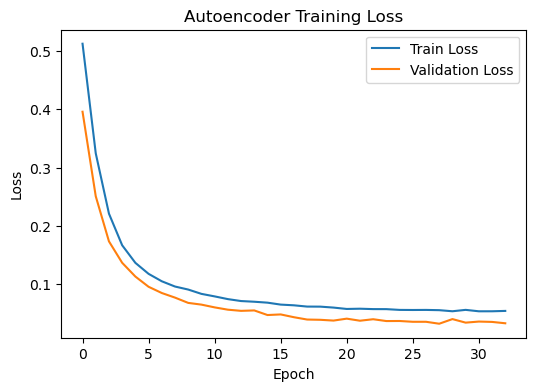

50/50 [==============================] - 0s 2ms/step
Latent features shape: (1576, 74)


In [5]:
from tensorflow import keras
from tensorflow.keras import layers
encoding_dim=74

def create_autoencoder(input_dim, encoding_dim=74):
    # Encoder
    input_layer = keras.Input(shape=(input_dim,), name="autoencoder_input")
    x = layers.Dense(128, activation='relu')(input_layer)
    x = layers.Dropout(0.1)(x)
    x = layers.Dense(96, activation='relu')(x)
    latent = layers.Dense(encoding_dim, activation='relu', name="latent_vector")(x)

    # Decoder
    x = layers.Dense(96, activation='relu')(latent)
    x = layers.Dense(128, activation='relu')(x)
    output_layer = layers.Dense(input_dim, activation='linear')(x)

    # Autoencoder Model
    autoencoder = keras.Model(input_layer, output_layer, name="autoencoder")
    autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    # autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=2e-3), loss="mse")


    # Also create an encoder to extract the latent representation
    encoder = keras.Model(input_layer, latent, name="encoder")
    return autoencoder, encoder

#  input_dim is determined after preprocessing (e.g., after scaling and hotencoding)
# As X_train is already defined
input_dim = X_train.shape[1]
autoencoder, encoder = create_autoencoder(input_dim, encoding_dim=74)

autoencoder.summary()

# Train the autoencoder on your training data
history_ae = autoencoder.fit(X_train, X_train,
                             validation_data=(X_val, X_val),
                             epochs=200,
                             batch_size=32,
                             callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
                             verbose=1)

# Plot training loss for the autoencoder
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(history_ae.history['loss'], label='Train Loss')
plt.plot(history_ae.history['val_loss'], label='Validation Loss')
plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Use the trained encoder to extract latent representations from X_train
X_train_latent = encoder.predict(X_train)
print("Latent features shape:", X_train_latent.shape)


In [12]:
# Print the final loss values after training
print("\nFinal Training Loss:", history_ae.history['loss'][-1])
print("Final Validation Loss:", history_ae.history['val_loss'][-1])

# Also, print loss at specific epochs (e.g., every 10 epochs)
for i in range(0, len(history_ae.history['loss']), 10):  # Every 10 epochs
    print(f"Epoch {i+1}: Train Loss = {history_ae.history['loss'][i]:.5f}, Validation Loss = {history_ae.history['val_loss'][i]:.5f}")



Final Training Loss: 0.0552876852452755
Final Validation Loss: 0.034575093537569046
Epoch 1: Train Loss = 0.51970, Validation Loss = 0.39881
Epoch 11: Train Loss = 0.07620, Validation Loss = 0.05852
Epoch 21: Train Loss = 0.05880, Validation Loss = 0.03707


1/1 [==============================] - 0s 107ms/step


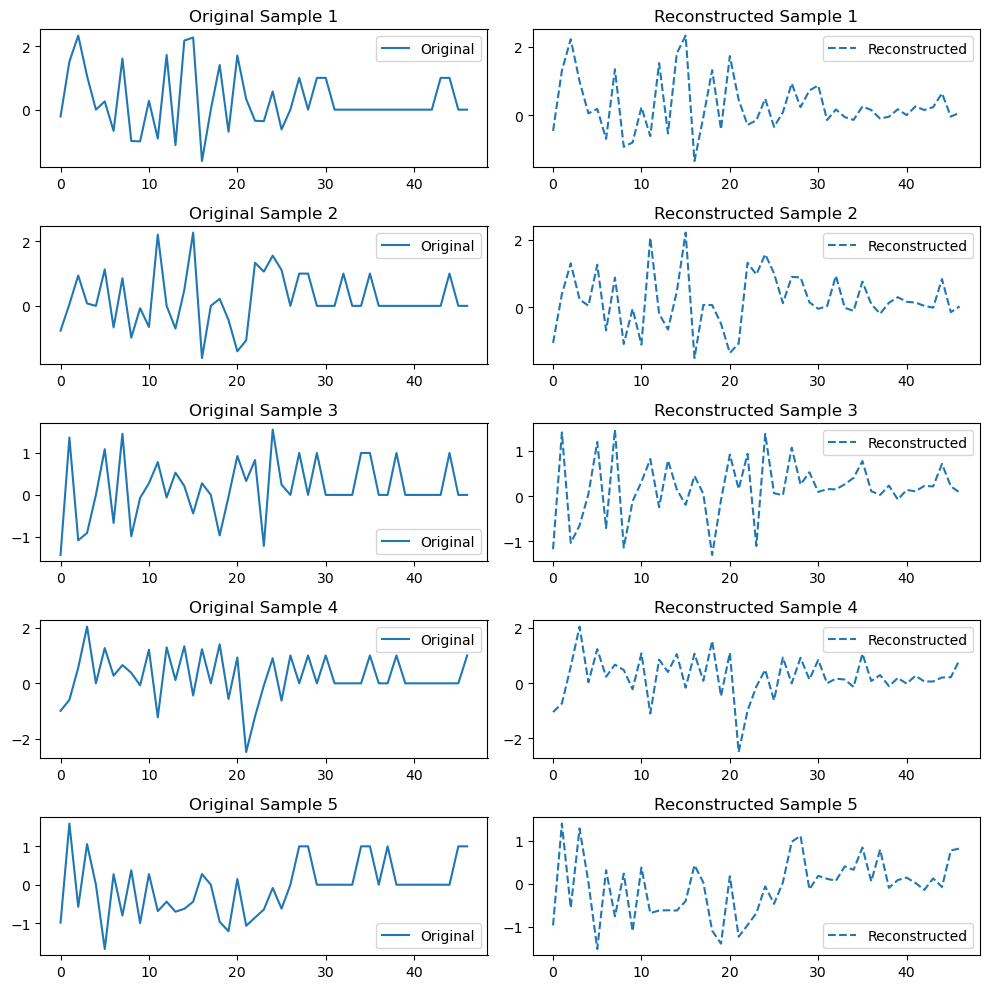

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Select a few random samples from X_test
num_samples = 5  # Choose how many examples to visualize
random_indices = np.random.choice(len(X_val), num_samples, replace=False)
original_samples = X_val[random_indices]

# Pass through the autoencoder
reconstructed_samples = autoencoder.predict(original_samples)

# Plot original vs. reconstructed samples
plt.figure(figsize=(10, num_samples * 2))

for i in range(num_samples):
    plt.subplot(num_samples, 2, 2 * i + 1)
    plt.plot(original_samples[i], label="Original")
    plt.title(f"Original Sample {i+1}")
    plt.legend()

    plt.subplot(num_samples, 2, 2 * i + 2)
    plt.plot(reconstructed_samples[i], label="Reconstructed", linestyle="dashed")
    plt.title(f"Reconstructed Sample {i+1}")
    plt.legend()

plt.tight_layout()
plt.show()


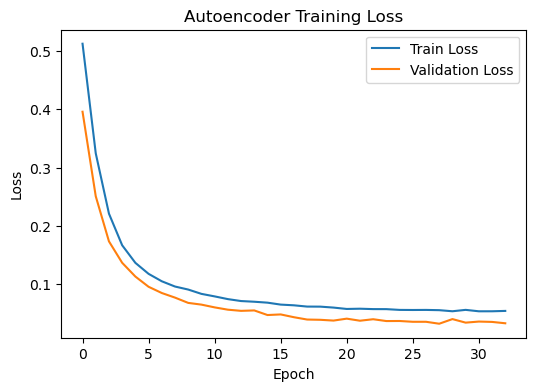

50/50 [==============================] - 0s 2ms/step
Latent features shape: (1576, 74)
Example latent vector: [2.5763664  0.         3.3565257  0.         2.4750316  1.4551258
 1.8320342  2.4655185  1.4240739  1.5577549  0.         0.9833662
 1.491329   1.37246    0.3117972  0.         4.4389415  2.398627
 0.         0.         0.         1.4122119  0.6896098  3.1296775
 0.52677864 2.9235845  0.         2.8286648  3.5139575  0.87473357
 1.687318   0.40588495 2.8187919  1.3674048  2.564264   0.
 2.453318   0.         2.4157982  0.         2.5231338  1.5400497
 2.8528678  2.4976335  0.45783168 2.4525332  2.526968   2.3085406
 1.0237548  1.4291251  0.07145438 0.         1.5137053  2.4317887
 1.5294528  2.1297781  4.2524633  2.2086544  2.8254688  0.
 2.995792   0.3660294  3.1281857  0.         2.8799977  0.
 0.45190224 0.         3.6096482  0.01164519 2.655369   2.2484186
 3.059852   1.4193469 ]


In [6]:
# Plot training and validation loss for the autoencoder
plt.figure(figsize=(6,4))
plt.plot(history_ae.history['loss'], label='Train Loss') # Changed history to history_ae
plt.plot(history_ae.history['val_loss'], label='Validation Loss') # Changed history to history_ae
plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# After training, get the latent features on the training data:
X_train_latent = encoder.predict(X_train)
print("Latent features shape:", X_train_latent.shape)

#  Print one example latent vector:
print("Example latent vector:", X_train_latent[0])

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Define Transformer block model – treat 74 dims as sequence tokens (74,1)
transformer_input = keras.Input(shape=(encoding_dim, 1), name="transformer_input")

# Use smaller key_dim and ensure heads divide encoding_dim
transformer_layer = layers.MultiHeadAttention(num_heads=8, key_dim=32)
attn_output = transformer_layer(transformer_input, transformer_input)

# Flatten to feed into next models
flattened_output = layers.Flatten(name="transformer_flatten")(attn_output)

# Build model
transformer_model = keras.Model(transformer_input, flattened_output, name="transformer_block")
transformer_model.summary()



Model: "transformer_block"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 transformer_input (InputLayer)  [(None, 74, 1)]     0           []                               
                                                                                                  
 multi_head_attention (MultiHea  (None, 74, 1)       1793        ['transformer_input[0][0]',      
 dAttention)                                                      'transformer_input[0][0]']      
                                                                                                  
 transformer_flatten (Flatten)  (None, 74)           0           ['multi_head_attention[0][0]']   
                                                                                                  
Total params: 1,793
Trainable params: 1,793
Non-trainable params: 0
______________

In [8]:
print("X_train_latent shape before reshaping:", X_train_latent.shape)


# Reshape correctly
num_samples = X_train_latent.shape[0]
X_train_latent_reshaped = X_train_latent.reshape(num_samples, encoding_dim, 1)
# equivalent - X_train_latent_reshaped = X_train_latent.reshape(-1, encoding_dim, 1)
print("Reshaped latent features shape:", X_train_latent_reshaped.shape)




# Run through Transformer
transformer_features = transformer_model.predict(X_train_latent_reshaped)
print("Transformer features shape:", transformer_features.shape)


X_train_latent shape before reshaping: (1576, 74)
Reshaped latent features shape: (1576, 74, 1)
50/50 [==============================] - 0s 5ms/step
Transformer features shape: (1576, 74)


In [9]:
# Define a DDQN (DQNN) model.
action_size = 2  # Number of possible actions

# State input for the DDQN head (you can adjust this shape as appropriate)
state_input = keras.Input(shape=(10,), name="ddqn_input")


# Value Branch: estimate state-value
value_dense = layers.Dense(64, activation="relu")(state_input)
value_output = layers.Dense(1, activation="linear")(value_dense)
# Advantage Branch: advantage for each action
advantage_dense = layers.Dense(64, activation="relu")(state_input)
advantage_output = layers.Dense(action_size, activation="linear")(advantage_dense)
# Subtract the mean advantage from the advantage output # Combine using the dueling technique: Q = value + (advantage - mean(advantage))
advantage_mean = layers.Lambda(lambda x: x - tf.reduce_mean(x, axis=1, keepdims=True))(advantage_output)
# Combine value and advantage streams
q_values = layers.Add()([value_output, advantage_mean])

# Create and compile the DDQN model
ddqn_model = keras.Model(state_input, q_values, name="DDQN_model")
ddqn_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
ddqn_model.summary()



Model: "DDQN_model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 ddqn_input (InputLayer)        [(None, 10)]         0           []                               
                                                                                                  
 dense_7 (Dense)                (None, 64)           704         ['ddqn_input[0][0]']             
                                                                                                  
 dense_5 (Dense)                (None, 64)           704         ['ddqn_input[0][0]']             
                                                                                                  
 dense_8 (Dense)                (None, 2)            130         ['dense_7[0][0]']                
                                                                                         

Combined state shape: (1576, 84)


Model: "Final_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ final_input (InputLayer)             │ (None, 84)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 256)                 │          21,760 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 64,513 (252.00 KB)

 Trainable params: 63,745 (249.00 KB)

...

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8687 - loss: 0.5109 - val_accuracy: 0.8576 - val_loss: 0.5652 - learning_rate: 0.0010
Epoch 10/300
77/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8664 - loss: 0.4812

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8662 - loss: 0.4817 - val_accuracy: 0.8576 - val_loss: 0.5570 - learning_rate: 0.0010
Epoch 11/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8672 - loss: 0.4675 - val_accuracy: 0.8544 - val_loss: 0.5592 - learning_rate: 0.0010
Epoch 12/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8671 - loss: 0.4724 - val_accuracy: 0.8133 - val_loss: 0.5982 - learning_rate: 0.0010
Epoch 13/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8717 - loss: 0.4664 - val_accuracy: 0.8323 - val_loss: 0.5820 - learning_rate: 0.0010
Epoch 14/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8629 - loss: 0.4641 - val_accuracy: 0.8544 - val_loss: 0.5676 - learning_rate: 0.0010
Epoch 15/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8908 - loss: 0.4270 - val_accuracy: 0.8354 - val_loss: 0.5802 - learning_rate: 0.0010
Epoch 16/300
75/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8802 - loss: 0.4243

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8805 - loss: 0.4233 - val_accuracy: 0.8608 - val_loss: 0.5319 - learning_rate: 2.0000e-04
Epoch 17/300
75/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9066 - loss: 0.3896

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9059 - loss: 0.3901 - val_accuracy: 0.8608 - val_loss: 0.5284 - learning_rate: 2.0000e-04
Epoch 18/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8940 - loss: 0.3907 - val_accuracy: 0.8608 - val_loss: 0.5286 - learning_rate: 2.0000e-04
Epoch 19/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9166 - loss: 0.3696 - val_accuracy: 0.8513 - val_loss: 0.5322 - learning_rate: 2.0000e-04
Epoch 20/300
69/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8996 - loss: 0.3794

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8995 - loss: 0.3807 - val_accuracy: 0.8481 - val_loss: 0.5262 - learning_rate: 2.0000e-04
Epoch 21/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9156 - loss: 0.3478 - val_accuracy: 0.8576 - val_loss: 0.5314 - learning_rate: 2.0000e-04
Epoch 22/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9076 - loss: 0.3613 - val_accuracy: 0.8576 - val_loss: 0.5320 - learning_rate: 2.0000e-04
Epoch 23/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9059 - loss: 0.3552 - val_accuracy: 0.8576 - val_loss: 0.5283 - learning_rate: 2.0000e-04
Epoch 24/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9214 - loss: 0.3499 - val_accuracy: 0.8544 - val_loss: 0.5344 - learning_rate: 2.0000e-04
Epoch 25/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9010 - loss: 0.3523 - val_accuracy: 0.8449 - val_loss: 0.5309 - learning_rate: 2.0000e-04
Epoch 26/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9229 - loss

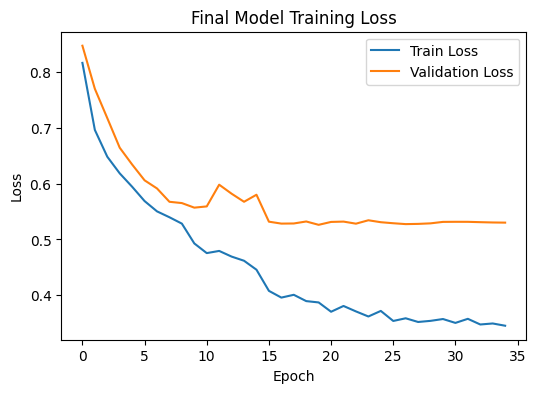

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8541 - loss: 0.5137 
Validation Loss: 0.5262 | Accuracy: 0.8481
Combined state shape: (1576, 84)


In [13]:
# Example of concatenating transformer features with additional state features.
# For demonstration we simulate an extra 10-dim state (e.g., other sensor readings)
dummy_state = np.random.rand(X_train_latent.shape[0], 10)
# Combine transformer features (shape: (n_samples, 64)) with dummy state → (n_samples, 64+10)
combined_state = np.concatenate([transformer_features, dummy_state], axis=1)
print("Combined state shape:", combined_state.shape)

# Convert y_train to numerical format before splitting
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
# y_processed = le.fit_transform(y)
y_train_encoded = le.fit_transform(y_train)

# our target is binary (Attrition - Yes/No)
from tensorflow.keras.losses import BinaryCrossentropy # Import the desired loss function
output_units = 1  # For binary classification
final_activation = 'sigmoid'  # For binary classification
loss_fn = BinaryCrossentropy() # Assign the desired loss function to the variable

# If our target has more than 2 classes:
# output_units = num_classes  # Replace with the number of classes in your target
# final_activation = 'softmax' # For multi-class classification


from tensorflow.keras import regularizers

final_input = keras.Input(shape=(combined_state.shape[1],), name="final_input")

# First layer with higher capacity
x = layers.Dense(256, activation='swish', kernel_regularizer=regularizers.l2(0.001))(final_input)
x = layers.BatchNormalization()(x)  # Normalize activations
x = layers.Dropout(0.2)(x)  # Increase dropout

# Second layer
x = layers.Dense(128, activation='swish', kernel_regularizer=regularizers.l2(0.001))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)

# Third layer
x = layers.Dense(64, activation='swish')(x)

# Output layer
output = layers.Dense(output_units, activation=final_activation)(x)

# Compile model
final_model = keras.Model(final_input, output, name="Final_Model")
final_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss=loss_fn, metrics=['accuracy'])
final_model.summary()





# Split combined state data to match supervised target training
# Use y_train instead of y_processed
combined_train, combined_val, y_train_supervised, y_val_supervised = train_test_split(
    combined_state, y_train_encoded, test_size=0.2, random_state=42
)
# combined_train, combined_val, y_train_supervised, y_val_supervised = train_test_split(
#     combined_state, y_processed, test_size=0.2, random_state=42)

# Use callbacks to prevent overfitting
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6),
    keras.callbacks.ModelCheckpoint('best_model.h5', save_best_only=True, monitor='val_loss', mode='min')
]

history_final = final_model.fit(combined_train, y_train_supervised,
                                validation_data=(combined_val, y_val_supervised),
                                epochs=300,  # Train longer
                                batch_size=16,  # Test 16, 32, and 64
                                callbacks=callbacks,
                                verbose=1)


# Plot the supervised training progress
plt.figure(figsize=(6,4))
plt.plot(history_final.history['loss'], label='Train Loss')
plt.plot(history_final.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Final Model Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

# Evaluate on validation set
test_loss, test_accuracy = final_model.evaluate(combined_val, y_val_supervised)
print("Validation Loss: {:.4f} | Accuracy: {:.4f}".format(test_loss, test_accuracy))


# For demonstration we simulate an extra 10-dim state (e.g., other sensor readings)
dummy_state = np.random.rand(X_train_latent.shape[0], 10)
# Combine transformer features (shape: (n_samples, 64)) with dummy state → (n_samples, 64+10)
combined_state = np.concatenate([transformer_features, dummy_state], axis=1)
print("Combined state shape:", combined_state.shape)